![Banner](../../../../Images/Banner/03_spatial_analysis/03_02_banner_spatial_analysis_DTM.png)

# DEM Preprocessing

Before slope, landforms, or watersheds make sense, a DEM has to be opened, understood, clipped, and visualized. This notebook is the practical preprocessing step for Module **03.02**. It reviews DEM / DTM / DSM and common elevation sources, then loads the Bangladesh hilly-district DEM with GeoLattice, inspects metadata and elevation statistics, clips and resamples the surface, and builds elevation, hillshade, 3D, and profile views.

Hands-on morphometry continues in [03_02_02_terrain_analysis.ipynb](03_02_02_terrain_analysis.ipynb); hydrologic conditioning and flow routing continue in [03_02_03_hydrology_modeling.ipynb](03_02_03_hydrology_modeling.ipynb).


## Table of Contents

1. [DEM, DTM, and DSM](#dem-dtm-and-dsm)
2. [Sources of elevation data](#sources-of-elevation-data)
3. [Setup](#setup)
4. [Loading a DEM GeoTIFF with GeoLattice](#loading-a-dem-geotiff-with-geolattice)
5. [Metadata, CRS, resolution, and elevation statistics](#metadata-crs-resolution-and-elevation-statistics)
6. [Clipping and resampling](#clipping-and-resampling)
7. [Elevation visualization and histograms](#elevation-visualization-and-histograms)
8. [Hillshade visualization](#hillshade-visualization)
9. [3D terrain visualization and elevation profiles](#3d-terrain-visualization-and-elevation-profiles)
10. [Where to go next](#where-to-go-next)


## DEM, DTM, and DSM

These three terms are often used loosely. Keep the distinctions clear when you choose a product and when you interpret derivatives.

| Surface | What it represents | Best for |
|---|---|---|
| **DEM** | Generic elevation raster; may be bare earth or mixed | Broad elevation context (check metadata) |
| **DTM** | Bare-ground surface only | Hydrology, geomorphometry, floodplain analysis |
| **DSM** | Uppermost surface including buildings and vegetation | Urban canopy, obstacle-aware viewsheds |

A simplified relationship is:

$$DSM \approx DTM + \text{above-ground object heights}$$

Public "DEMs" such as SRTM often behave closer to a DSM in forested or built-up areas. For drainage and landform work, prefer a bare-earth DTM when one is available. Conceptual background is in [03_02_00_digital_terrain_modeling_introduction.ipynb](03_02_00_digital_terrain_modeling_introduction.ipynb).


## Sources of elevation data

Global and near-global elevation products differ in resolution, vertical accuracy, void handling, and whether they lean toward DTM or DSM behaviour.

| Product | Typical resolution | Coverage / notes | DTM vs DSM tendency |
|---|---|---|---|
| **SRTM** (NASA / NGA) | ~30 m (1 arc-sec), also 90 m | ~60°N-56°S; C-band radar (2000); voids filled in later releases | Mixed; canopy bias in forest |
| **Copernicus DEM** (ESA / Airbus) | 30 m (GLO-30), 90 m (GLO-90) | Near-global; edited WorldDEM; good void handling | Closer to bare earth in many edited areas; still check docs |
| **ASTER GDEM** (NASA / METI) | ~30 m | Near-global; stereo optical; more artefacts in steep / cloudy terrain | Mixed; often noisier than SRTM / Copernicus |

Other common sources include national lidar DTMs (metre to sub-metre), TanDEM-X, ALOS World 3D, and ICESat-2 photon products. For Bangladesh regional work in this chapter we use a **250 m BTM mosaic** derived from SRTM-class elevation over the hilly districts (`hilly_dem_BTM.tiff`). Finer products are better for local engineering; coarser grids are enough for regional morphometry and teaching.


## Setup

Locate the repository root, import raster and terrain helpers, and create an output folder for preprocessing products.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

from pathlib import Path  # filesystem paths for the DEM and outputs

# Third-party numeric / plotting stack.
import matplotlib.pyplot as plt  # maps, histograms, profiles, and 3D axes
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  register 3D projection
import numpy as np  # array ops for profiles and the 3D surface
import pandas as pd  # tabular display of summarize_raster results
from IPython.display import display  # rich table preview

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Raster I/O and preprocessing helpers.
from geolattice.raster import (
    aggregate,  # coarsen by an integer factor
    clip,  # crop by projected bounds
    open_raster_data,  # open a GeoTIFF for metadata / arrays
    resample,  # warp to a target resolution
    summarize_raster,  # count/min/max/mean/percentiles
)
# Terrain helper used for shaded relief.
from geolattice.spatial_analysis import hillshade  # gdaldem-style hillshade
from geolattice.viz import apply_map_style, plot_raster, plot_raster_histogram, plot_rasters

apply_map_style()  # apply the GeoLattice tutorial matplotlib map defaults

# Bangladesh DEM and a dedicated preprocessing output folder.
BD = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh"
OUT = ROOT / "Data" / "00_shared" / "raster_data" / "output_folder" / "bangladesh" / "dem_preprocess"
OUT.mkdir(parents=True, exist_ok=True)
DEM = BD / "hilly_dem_BTM.tiff"  # 250 m BTM DEM for the hilly districts
assert DEM.exists(), f"Missing DEM: {DEM}"


def show_raster(path, title=None):
    """Print a short metadata summary for a GeoTIFF."""
    path = Path(path)
    with open_raster_data(path) as ds:
        gt = ds.geotransform
        print(f"path:    {path.name}")
        print(f"size:    {ds.width} x {ds.height}  bands={ds.band_count}")
        print(f"res:     {abs(gt[1]):.4f} x {abs(gt[5]):.4f}")
        print(f"bounds:  {ds.bounds}")
        print(f"crs:     {ds.crs}")
        print(f"nodata:  {ds.get_band(1).nodata}")
        if title:
            print(f"title:   {title}")


print(f"DEM:    {DEM}")
print(f"Output: {OUT}")


DEM:    /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/hilly_dem_BTM.tiff
Output: /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/bangladesh/dem_preprocess


## Loading a DEM GeoTIFF with GeoLattice

`open_raster_data` opens a GeoTIFF (or other GDAL raster) as a `RasterDataset`. Use it as a context manager when you only need metadata or a quick array read. Paths also pass directly into `clip`, `resample`, `summarize_raster`, `plot_raster`, and `hillshade`.


In [2]:
# Open the DEM and print the core RasterDataset attributes.
with open_raster_data(DEM) as ds:
    print(type(ds))
    print(f"driver:  {getattr(ds, 'driver', None)}")
    print(f"width:   {ds.width}")
    print(f"height:  {ds.height}")
    print(f"bands:   {ds.band_count}")
    print(f"crs:     {ds.crs}")
    print(f"gt:      {ds.geotransform}")
    print(f"bounds:  {ds.bounds}")
    band = ds.get_band(1)
    print(f"dtype:   {band.dtype}")
    print(f"nodata:  {band.nodata}")


<class 'geolattice.raster.raster_read_write.RasterDataset'>
driver:  GTiff
width:   521
height:  1329
bands:   1
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
gt:      (648050.3746814046, 250.0, 0.0, 627267.2625412983, 0.0, -249.99999999999991)
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
dtype:   float32
nodata:  nan


## Metadata, CRS, resolution, and elevation statistics

Elevation analysis needs a **metric CRS** so cell size is in metres and slope / distance calculations stay meaningful. This DEM is in **Bangladesh Transverse Mercator (BTM)** at **250 m** resolution. `summarize_raster` reports count, min, max, mean, standard deviation, and selected percentiles after excluding nodata.


In [3]:
# Summarize elevation values and show them as a one-row table.
show_raster(DEM, "Full hilly-district DEM")
stats = summarize_raster(DEM, percentiles=(2, 25, 50, 75, 98))
row = {
    "count": stats["count"],
    "min_m": stats["min"],
    "max_m": stats["max"],
    "mean_m": stats["mean"],
    "std_m": stats["std"],
    **{k: v for k, v in stats["percentiles"].items()},
}
display(pd.DataFrame([row]).round(2))


path:    hilly_dem_BTM.tiff
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan
title:   Full hilly-district DEM


,count,min_m,max_m,mean_m,std_m,p2,p25,p50,p75,p98
0,310665,-7.8,985.05,109.01,129.05,3.04,29.24,64.78,137.12,544.44


## Clipping and resampling

Clipping focuses later work on an area of interest (AOI). Resampling changes cell size: coarser grids run faster and match regional analyses; finer grids need a higher-resolution source (resampling alone does not invent true detail).

Here we:

1. Clip a central ~40 km × 60 km window (same idea as the terrain-analysis notebook).
2. Aggregate the AOI by factor 2 (~500 m) with averaging.
3. Resample that coarse grid back toward 250 m with bilinear interpolation for comparison.


In [4]:
# Build a central analysis window (~40 km x 60 km) from the full DEM bounds.
with open_raster_data(DEM) as ds:
    b = ds.bounds  # full DEM extent in BTM metres
    mid_x = 0.5 * (b.minx + b.maxx)
    mid_y = 0.5 * (b.miny + b.maxy)
    half_x, half_y = 20000.0, 30000.0  # half-width / half-height in metres
    aoi_bounds = (mid_x - half_x, mid_y - half_y, mid_x + half_x, mid_y + half_y)

dem = OUT / "aoi_dem_250m.tif"
clip(DEM, dem, bounds=aoi_bounds, overwrite=True)
show_raster(dem, "Clipped AOI DEM (250 m)")

# Coarsen to ~500 m, then resample back toward the original 250 m grid.
agg_500 = OUT / "aoi_dem_500m.tif"
resamp_250 = OUT / "aoi_dem_resampled_250m.tif"
aggregate(dem, agg_500, factor=2, method="average", overwrite=True)
with open_raster_data(dem) as ds:
    xres, yres = abs(ds.geotransform[1]), abs(ds.geotransform[5])
resample(agg_500, resamp_250, resolution=(xres, yres), method="bilinear", overwrite=True)

for label, path in [
    ("250 m (clip)", dem),
    ("500 m (aggregate)", agg_500),
    ("~250 m (resampled from 500 m)", resamp_250),
]:
    print(f"\n=== {label} ===")
    show_raster(path)


path:    aoi_dem_250m.tif
size:    160 x 240  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(693175.3746814046, 431142.26254129835, 733175.3746814046, 491142.26254129835)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan
title:   Clipped AOI DEM (250 m)

=== 250 m (clip) ===
path:    aoi_dem_250m.tif
size:    160 x 240  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(693175.3746814046, 431142.26254129835, 733175.3746814046, 491142.26254129835)
crs:     PROJCS["unknown",GEO

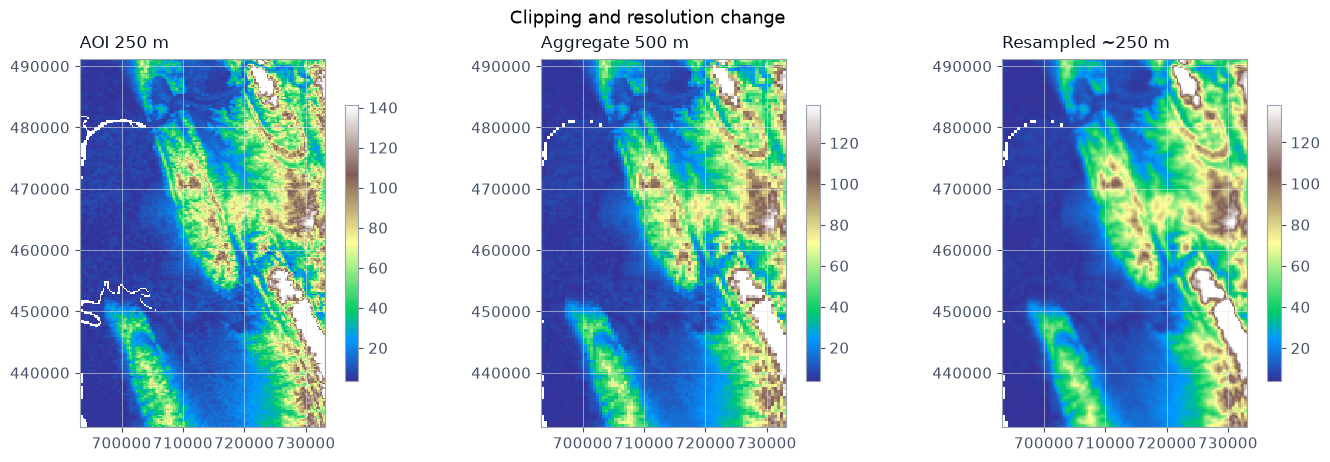

In [5]:
# Compare the clipped DEM with its coarser and resampled versions.
plot_rasters(
    [dem, agg_500, resamp_250],
    titles=["AOI 250 m", "Aggregate 500 m", "Resampled ~250 m"],
    ncols=3,
    cmap="terrain",
    robust=True,
    figsize=(14, 4.5),
    show=False,
)
plt.suptitle("Clipping and resolution change", y=1.02)
plt.show()


## Elevation visualization and histograms

A continuous elevation map with a terrain colormap shows absolute height. A histogram shows how those heights are distributed and whether voids or spikes dominate the AOI. Use `robust=True` on `plot_raster` when a few extreme cells would otherwise crush the color stretch.


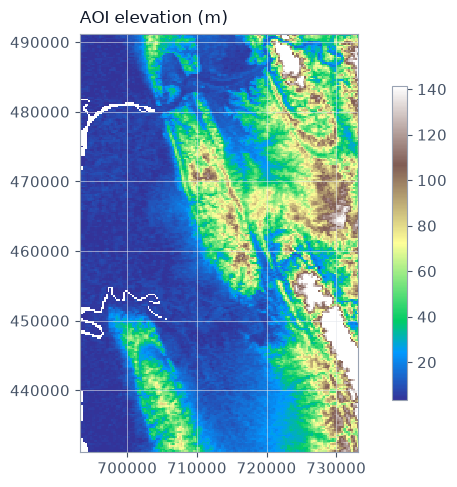

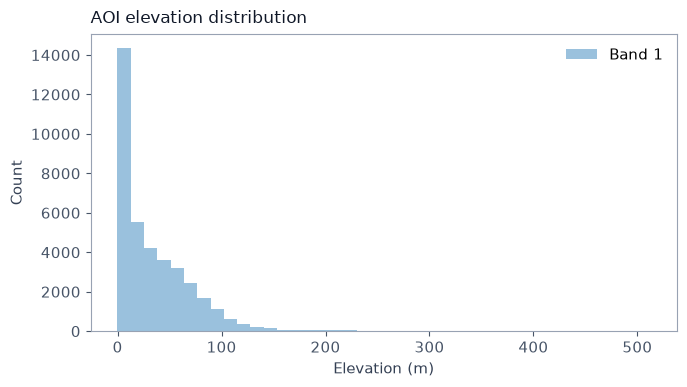

In [6]:
# Map elevation for the clipped AOI.
ax = plot_raster(
    dem,
    title="AOI elevation (m)",
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
plt.show()

# Elevation histogram for the same AOI.
ax = plot_raster_histogram(
    dem,
    bins=40,
    title="AOI elevation distribution",
    show=False,
)
ax.set_xlabel("Elevation (m)")
plt.show()


## Hillshade visualization

Hillshade simulates illumination of the terrain so ridges and valleys read as relief. A single sun direction (often azimuth 315°, altitude 45°) is the cartographic default; a **multidirectional** hillshade blends several azimuths and reduces directional bias. Hillshade is a visualization aid; slope and aspect remain the quantitative derivatives (next notebook).


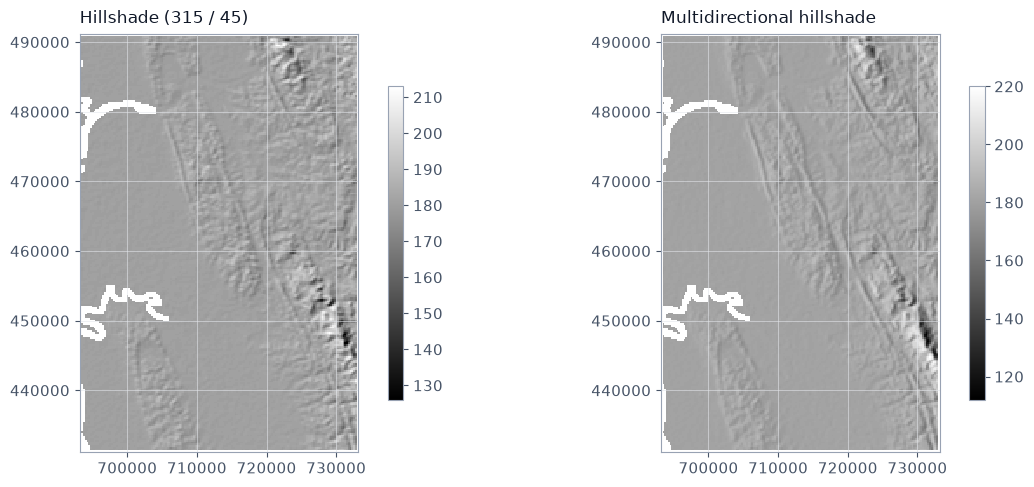

In [7]:
# Compute single-direction and multidirectional hillshade for the AOI.
hs = OUT / "aoi_hillshade.tif"
hs_md = OUT / "aoi_hillshade_multidirectional.tif"
hillshade(dem, hs, azimuth=315, altitude=45, overwrite=True)
hillshade(dem, hs_md, multidirectional=True, overwrite=True)

plot_rasters(
    [hs, hs_md],
    titles=["Hillshade (315 / 45)", "Multidirectional hillshade"],
    ncols=2,
    cmap="gray",
    figsize=(12, 5),
    show=False,
)
plt.show()


## 3D terrain visualization and elevation profiles

A 3D surface plot makes relative relief obvious; elevation profiles quantify height along a transect. Both use the clipped AOI array. The 3D view is downsampled so the notebook stays responsive. Profiles are sampled along west-east and south-north lines through the AOI centre.


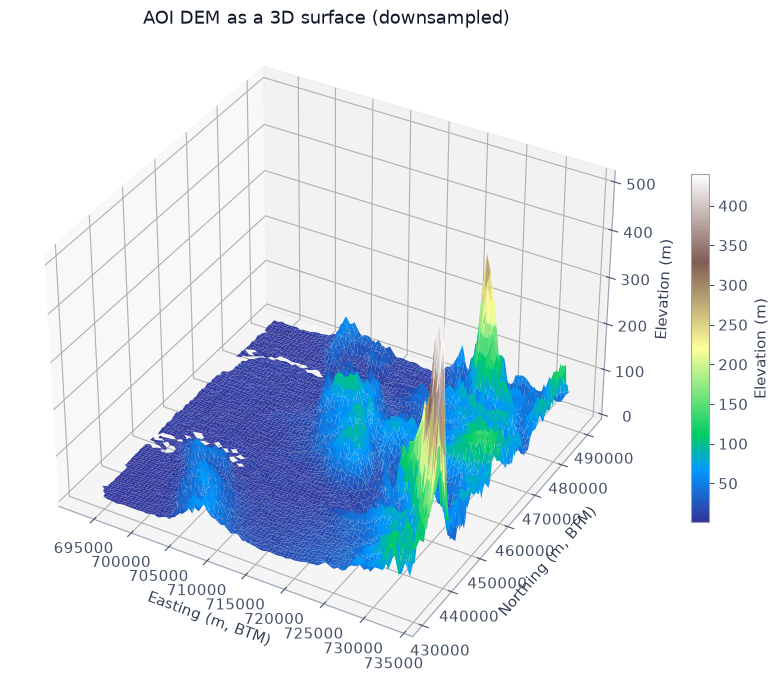

In [8]:
# Read the AOI DEM into a masked NumPy array for 3D and profile work.
with open_raster_data(dem) as ds:
    gt = ds.geotransform
    nodata = ds.get_band(1).nodata
    elev = np.asarray(ds.read(bands=1), dtype=np.float64)
    xmin, xmax = ds.bounds.minx, ds.bounds.maxx
    ymin, ymax = ds.bounds.miny, ds.bounds.maxy

if nodata is not None:
    elev = np.where(elev == nodata, np.nan, elev)
elev = np.where(np.isfinite(elev), elev, np.nan)

# Downsample for a responsive 3D surface (every nth cell).
step = max(1, min(elev.shape) // 80)
z = elev[::step, ::step]
rows, cols = z.shape
x = np.linspace(xmin, xmax, cols)
y = np.linspace(ymax, ymin, rows)  # north at top of the array
X, Y = np.meshgrid(x, y)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(
    X, Y, z,
    cmap="terrain",
    linewidth=0,
    antialiased=True,
    rstride=1,
    cstride=1,
)
ax.set_xlabel("Easting (m, BTM)")
ax.set_ylabel("Northing (m, BTM)")
ax.set_zlabel("Elevation (m)")
ax.set_title("AOI DEM as a 3D surface (downsampled)")
fig.colorbar(surf, ax=ax, shrink=0.55, label="Elevation (m)")
ax.view_init(elev=35, azim=-60)
plt.tight_layout()
plt.show()


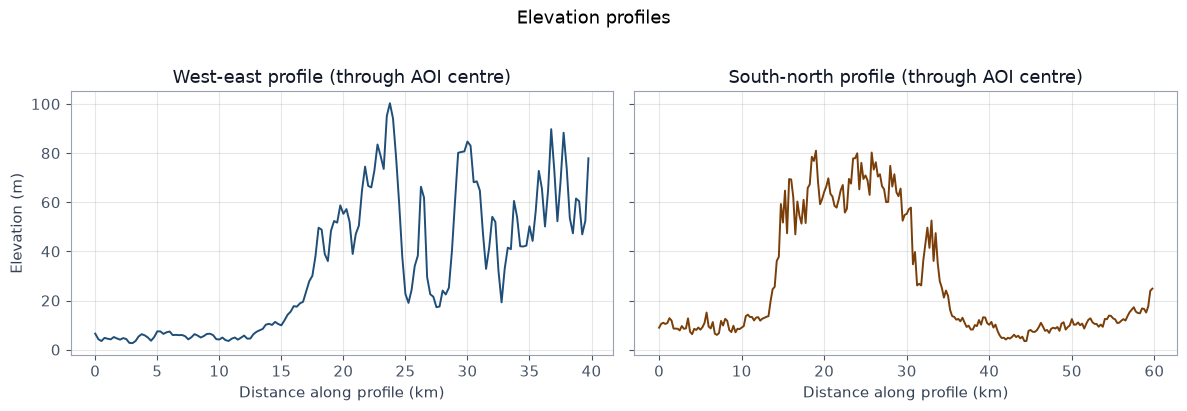

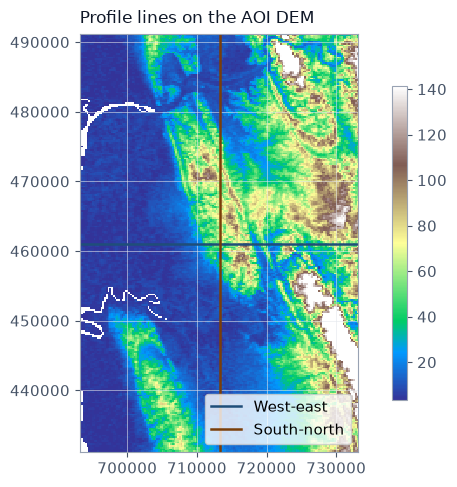

In [9]:
# Sample west-east and south-north elevation profiles through the AOI centre.
nrows, ncols = elev.shape
xres, yres = abs(gt[1]), abs(gt[5])
row_c, col_c = nrows // 2, ncols // 2

# West-east profile: fixed row, all columns.
we_z = elev[row_c, :]
we_dist = np.arange(ncols) * xres / 1000.0  # distance along profile in km
# South-north profile: fixed column, all rows (top = north).
sn_z = elev[:, col_c]
sn_dist = np.arange(nrows) * yres / 1000.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].plot(we_dist, we_z, color="#1f4e79", lw=1.4)
axes[0].set_title("West-east profile (through AOI centre)")
axes[0].set_xlabel("Distance along profile (km)")
axes[0].set_ylabel("Elevation (m)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(sn_dist, sn_z, color="#7a3e09", lw=1.4)
axes[1].set_title("South-north profile (through AOI centre)")
axes[1].set_xlabel("Distance along profile (km)")
axes[1].grid(True, alpha=0.3)
fig.suptitle("Elevation profiles", y=1.02)
fig.tight_layout()
plt.show()

# Show where the profiles cross the elevation map.
ax = plot_raster(
    dem,
    title="Profile lines on the AOI DEM",
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
# Convert pixel centres of the profile lines to map coordinates.
we_xs = xmin + (np.arange(ncols) + 0.5) * xres
we_ys = np.full(ncols, ymax - (row_c + 0.5) * yres)
sn_xs = np.full(nrows, xmin + (col_c + 0.5) * xres)
sn_ys = ymax - (np.arange(nrows) + 0.5) * yres
ax.plot(we_xs, we_ys, color="#1f4e79", lw=1.8, label="West-east")
ax.plot(sn_xs, sn_ys, color="#7a3e09", lw=1.8, label="South-north")
ax.legend(loc="lower right", frameon=True)
plt.show()


## Where to go next

| Next notebook | What you will do with this AOI DEM |
|---|---|
| [03_02_02_terrain_analysis.ipynb](03_02_02_terrain_analysis.ipynb) | Slope, aspect, TRI/TPI/roughness, curvature, TWI, landforms, viewshed, contours |
| [03_02_03_hydrology_modeling.ipynb](03_02_03_hydrology_modeling.ipynb) | Breach/fill depressions, flow direction and accumulation, streams, watersheds |

Preprocessing checklist before those notebooks:

- Confirm CRS units are metres and vertical units are metres.
- Clip to an AOI that fits memory and runtime.
- Inspect the histogram for voids, spikes, or ocean / nodata leakage.
- Keep a hillshade beside quantitative maps so relief stays readable.
